# Data Pipeline & Preprocessing ETL

In [1]:
# Cell 1: Import Semua Library yang Dibutuhkan
import requests
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Konfigurasi visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
print("Semua library berhasil dimuat.")

Semua library berhasil dimuat.


# 1. Countries Dataset
Mengambil data master profil negara, kode ISO, koordinat ibukota, mata uang, dan populasi.

In [2]:
# Konfigurasi API REST Countries v5
REST_COUNTRIES_API_KEY = "rc_live_4ab29ccdd625477285c00a59d38b5ff7"
REST_COUNTRIES_URL = "https://api.restcountries.com/countries/v5"
FIELDS = "names.common,codes.alpha_2,codes.alpha_3,capitals.coordinates,currencies.code,population,region"

headers = {"Authorization": f"Bearer {REST_COUNTRIES_API_KEY}"}
countries_list = []
offset = 0
limit = 100

while True:
    url = f"{REST_COUNTRIES_URL}?response_fields={FIELDS}&limit={limit}&offset={offset}"
    res = requests.get(url, headers=headers).json()
    objects = res.get('data', {}).get('objects', [])
    if not objects:
        break

    for item in objects:
        capitals = item.get('capitals', [])
        coords = capitals[0].get('coordinates', {}) if capitals else {}
        currencies = item.get('currencies', [])
        curr_code = currencies[0].get('code') if currencies else None

        countries_list.append({
            'country': item.get('names', {}).get('common'),
            'alpha_2': item.get('codes', {}).get('alpha_2'),
            'alpha_3': item.get('codes', {}).get('alpha_3'),
            'currency_code': curr_code,
            'capital_lat': coords.get('lat'),
            'capital_lng': coords.get('lng'),
            'population': item.get('population'),
            'region': item.get('region')
        })

    if not res.get('data', {}).get('meta', {}).get('more', False):
        break

    offset += limit
    time.sleep(0.2)

df_countries = pd.DataFrame(countries_list)
print(f"Master data berhasil diambil: {len(df_countries)} negara.")
df_countries.head()

Master data berhasil diambil: 254 negara.


,country,alpha_2,alpha_3,currency_code,capital_lat,capital_lng,population,region
0,Abkhazia,,,RUB,43.0033,41.0153,244236,Asia
1,Afghanistan,AF,AFG,AFN,34.5200,69.1800,43844000,Asia
2,Albania,AL,ALB,ALL,41.3200,19.8200,2335930,Europe
3,Algeria,DZ,DZA,DZD,36.7500,3.0500,47400000,Africa
4,American Samoa,AS,ASM,USD,-14.2700,-170.7000,43268,Oceania


# 2. Latest Currency Exchange Rates
Mengambil nilai tukar terbaru terhadap USD dari Frankfurter API dan menggabungkannya ke dataset negara.

## 2.1 Check Struktur API Exchange

In [3]:
headers = {'User-Agent': 'Mozilla/5.0'}
rates_url = 'https://api.frankfurter.dev/v2/rates?base=USD'
rates_raw = requests.get(rates_url, headers=headers).json()
df_rates_raw = pd.DataFrame(rates_raw)

# 1. Preview data mentah API
print("1. Preview 3 Data Teratas dari API:")
display(df_rates_raw[['date', 'base', 'quote', 'rate']].head(3))


1. Preview 3 Data Teratas dari API:


,date,base,quote,rate
0,2026-10-21,USD,AED,3.6725
1,2026-10-21,USD,AFN,64.9330
2,2026-10-21,USD,ALL,80.8300


Kalau dilihat dari hasilnya Quote itu adalaah ISO 4217 (Currency). Dari API tersebut kita ga bsia dapatkan ISO2 untuk merge dengan data country. Maka dari itu menggunakan quote untuk join dengan currency code.

## 2.2 Ekstraksi Kurs & Merge ke Dataset Country

In [4]:
df_rates = df_rates_raw.copy()

# rename quote dan rate untuk konsistensi join
df_rates = df_rates[['quote', 'rate']].rename(columns={
    'quote': 'currency_code',
    'rate': 'usd_exchange_rate'
})

# Merge dataset country (Left Join)
df_merged = df_countries.merge(df_rates, on='currency_code', how='left')

# negara pengguna USD (misal United States, American Samoa), set rate = 1.0
df_merged.loc[df_merged['currency_code'] == 'USD', 'usd_exchange_rate'] = 1.0
display(df_merged[['country', 'alpha_2', 'alpha_3', 'currency_code', 'usd_exchange_rate']].head(10))

,country,alpha_2,alpha_3,currency_code,usd_exchange_rate
0,Abkhazia,,,RUB,82.7000
1,Afghanistan,AF,AFG,AFN,64.9330
2,Albania,AL,ALB,ALL,80.8300
3,Algeria,DZ,DZA,DZD,134.6000
4,American Samoa,AS,ASM,USD,1.0000
5,Andorra,AD,AND,EUR,0.8908
6,Angola,AO,AGO,AOA,918.5000
7,Anguilla,AI,AIA,XCD,2.7472
8,Antarctica,AQ,ATA,None,NaN
9,Antigua and Barbuda,AG,ATG,XCD,2.7472


# 3. Current Weather Conditions (Open-Meteo)
Mengambil suhu dan kecepatan angin terkini ibukota menggunakan koordinat lat/lng dari dataset negara.

In [5]:
# Salin data koordinat valid
valid_coords = df_merged[df_merged['capital_lat'].notna() & df_merged['capital_lng'].notna()].copy()
CHUNK_SIZE = 50
weather_results = {}

indices = valid_coords.index.tolist()
for i in range(0, len(indices), CHUNK_SIZE):
    chunk_idx = indices[i:i + CHUNK_SIZE]
    chunk_df = valid_coords.loc[chunk_idx]

    lats_str = ','.join(chunk_df['capital_lat'].astype(str))
    lngs_str = ','.join(chunk_df['capital_lng'].astype(str))

    w_url = f"https://api.open-meteo.com/v1/forecast?latitude={lats_str}&longitude={lngs_str}&current=temperature_2m,wind_speed_10m"
    try:
        w_res = requests.get(w_url, timeout=10).json()
        # Jika hanya 1 koordinat, format respons adalah dict. Jika multi, respons adalah list of dicts.
        if isinstance(w_res, dict):
            w_res = [w_res]

        for idx, item in zip(chunk_idx, w_res):
            current = item.get('current', {})
            weather_results[idx] = {
                'capital_temp_c': current.get('temperature_2m'),
                'capital_wind_speed_kmh': current.get('wind_speed_10m')
            }
    except Exception as e:
        print(f"Warning batch {i}: {e}")

    time.sleep(0.2)

# Gabungkan hasil cuaca ke df_merged
df_weather = pd.DataFrame.from_dict(weather_results, orient='index')
df_merged = df_merged.join(df_weather)
df_merged[['country', 'capital_lat', 'capital_lng', 'capital_temp_c', 'capital_wind_speed_kmh']].head()

,country,capital_lat,capital_lng,capital_temp_c,capital_wind_speed_kmh
0,Abkhazia,43.0033,41.0153,20.3,5.9
1,Afghanistan,34.5200,69.1800,20.7,6.6
2,Albania,41.3200,19.8200,21.5,4.3
3,Algeria,36.7500,3.0500,23.1,13.5
4,American Samoa,-14.2700,-170.7000,25.9,32.0


# 4. Ingest COVID-19 Data (disease.sh)
Mengambil total kasus dan kematian COVID-19, lalu melakukan merge berdasarkan kode ISO-3 (alpha_3).

In [6]:
covid_url = "https://disease.sh/v3/covid-19/countries"
covid_res = requests.get(covid_url).json()

covid_records = []
for item in covid_res:
    info = item.get('countryInfo', {})
    covid_records.append({
        'alpha_3': info.get('iso3'),
        'covid_cases': item.get('cases'),
        'covid_deaths': item.get('deaths')
    })

df_covid = pd.DataFrame(covid_records)

# Merge ke master dataset berdasarkan alpha_3 (Left Join)
df_final = df_merged.merge(df_covid, on='alpha_3', how='left')

print(f"Merge COVID-19 selesai. Total baris data: {len(df_final)}")
display(df_final[['country', 'alpha_3', 'covid_cases', 'covid_deaths']].head())

Merge COVID-19 selesai. Total baris data: 254


,country,alpha_3,covid_cases,covid_deaths
0,Abkhazia,,NaN,NaN
1,Afghanistan,AFG,234174.0,7996.0
2,Albania,ALB,334863.0,3605.0
3,Algeria,DZA,272010.0,6881.0
4,American Samoa,ASM,NaN,NaN


# 5. Data Preprocessing & Feature Engineering
Melakukan penanganan missing values, pembuatan fitur rasio baru, encoding variabel kategorikal, dan feature scaling.

## 5.1 Handle Missing Values

In [7]:
# 1. Pengecekan Missing Values di SEMUA Kolom (Urut dari yang paling banyak)
missing_summary = pd.DataFrame({
    'Tipe Data': df_final.dtypes,
    'Jumlah Missing': df_final.isna().sum(),
    'Persentase (%)': (df_final.isna().sum() / len(df_final) * 100).round(2)
})
missing_summary = missing_summary[missing_summary['Jumlah Missing'] > 0].sort_values(by='Jumlah Missing', ascending=False)

print("1. Ringkasan Kolom dengan Missing Values:")
display(missing_summary)

1. Ringkasan Kolom dengan Missing Values:


,Tipe Data,Jumlah Missing,Persentase (%)
covid_cases,float64,25,9.84
covid_deaths,float64,25,9.84
capital_lat,float64,5,1.97
capital_lng,float64,5,1.97
capital_wind_speed_kmh,float64,5,1.97
usd_exchange_rate,float64,5,1.97
capital_temp_c,float64,5,1.97
currency_code,object,3,1.18


In [8]:
# 2. Negara yang usd_exchange_rate nya kosong
missing_rate_countries = df_final[df_final['usd_exchange_rate'].isna()][['country', 'region', 'currency_code', 'usd_exchange_rate']]
print("\n2. Daftar Negara dengan Nilai Kurs Kosong (NaN):")
display(missing_rate_countries)


2. Daftar Negara dengan Nilai Kurs Kosong (NaN):


,country,region,currency_code,usd_exchange_rate
8,Antarctica,Antarctic,None,NaN
29,Bouvet Island,Antarctic,None,NaN
52,Cook Islands,Oceania,CKD,NaN
97,Heard Island and McDonald Islands,Antarctic,None,NaN
206,Somaliland,Africa,SLSH,NaN


**Strategi Penanganan Missing Values :**
- `usd_exchange_rate`: Diisi `0.0` untuk wilayah tanpa mata uang resmi (e.g. Antartika) atau mata uang non-konvertibel.
- `covid_cases` & `covid_deaths`: Diisi `0` karena merupakan wilayah mikro/terpencil tanpa pelaporan kasus.
- `capital_temp_c` & `capital_wind_speed_kmh`: Diimputasi dengan **median per-wilayah (region)**.
- `currency_code`: Diisi `'UNKNOWN'`.
- `alpha_2` & `alpha_3`: Diisi `'UNKNOWN'` untuk wilayah berstatus sengketa/belum diakui PBB (e.g. Abkhazia) yang tidak memiliki kode resmi ISO 3166-1.
- `capital_lat` & `capital_lng`: Dibiarkan apa adanya (tidak boleh membuat koordinat geografis palsu).

Somaliland memiliki currency CODE tetapi karena mata uangnya tidak diakui secara internasional maka dia kosong, begitu juga dengan Cook islands mata uang hanya berlaku di dalam pulau.

untuk Antartica, Bouvet Island, Heard Island adalah negara tak berpenghuni.


In [9]:
df_prep = df_final.copy()

# 1. Kurs dan COVID diisi 0 (wilayah tanpa mata uang / tanpa laporan kasus)
df_prep['usd_exchange_rate'] = df_prep['usd_exchange_rate'].fillna(0.0)
df_prep['covid_cases'] = df_prep['covid_cases'].fillna(0)
df_prep['covid_deaths'] = df_prep['covid_deaths'].fillna(0)
df_prep['currency_code'] = df_prep['currency_code'].fillna('UNKNOWN')

# 2. Kode identitas ISO wilayah sengketa/tanpa kode resmi diisi 'UNKNOWN'
df_prep['alpha_2'] = df_prep['alpha_2'].replace('', 'UNKNOWN').fillna('UNKNOWN')
df_prep['alpha_3'] = df_prep['alpha_3'].replace('', 'UNKNOWN').fillna('UNKNOWN')

# 3. Cuaca diimputasi dengan median per-region (fallback ke median global jika 1 region kosong semua)
df_prep['capital_temp_c'] = df_prep['capital_temp_c'].fillna(df_prep.groupby('region')['capital_temp_c'].transform('median'))
df_prep['capital_temp_c'] = df_prep['capital_temp_c'].fillna(df_prep['capital_temp_c'].median())

df_prep['capital_wind_speed_kmh'] = df_prep['capital_wind_speed_kmh'].fillna(df_prep.groupby('region')['capital_wind_speed_kmh'].transform('median'))
df_prep['capital_wind_speed_kmh'] = df_prep['capital_wind_speed_kmh'].fillna(df_prep['capital_wind_speed_kmh'].median())

# 4. Validasi hasil imputasi pada fitur numerik utama
check_cols = ['usd_exchange_rate', 'covid_cases', 'covid_deaths', 'capital_temp_c', 'capital_wind_speed_kmh']
print("Sisa Missing Value Pada Kolom Numerik Utama Setelah Imputasi:")
display(df_prep[check_cols].isna().sum().to_frame(name='Sisa Missing'))

Sisa Missing Value Pada Kolom Numerik Utama Setelah Imputasi:


,Sisa Missing
usd_exchange_rate,0
covid_cases,0
covid_deaths,0
capital_temp_c,0
capital_wind_speed_kmh,0


## 5.2 Extract Features (Feature Engineering)

In [10]:
# Ekstraksi fitur rasio: Fatality Rate (%) & Infection Rate (%)
df_prep['fatality_rate_pct'] = (df_prep['covid_deaths'] / df_prep['covid_cases'].replace(0, np.nan)) * 100
df_prep['infection_rate_pct'] = (df_prep['covid_cases'] / df_prep['population'].replace(0, np.nan)) * 100
df_prep['fatality_rate_pct'] = df_prep['fatality_rate_pct'].fillna(0)
df_prep['infection_rate_pct'] = df_prep['infection_rate_pct'].fillna(0)

print("Contoh hasil ekstraksi fitur baru:")
display(df_prep[['country', 'covid_cases', 'population', 'fatality_rate_pct', 'infection_rate_pct']].head())

Contoh hasil ekstraksi fitur baru:


,country,covid_cases,population,fatality_rate_pct,infection_rate_pct
0,Abkhazia,0.0,244236,0.000000,0.000000
1,Afghanistan,234174.0,43844000,3.414555,0.534107
2,Albania,334863.0,2335930,1.076560,14.335318
3,Algeria,272010.0,47400000,2.529686,0.573861
4,American Samoa,0.0,43268,0.000000,0.000000


## 5.3 Encode Categorical Variables

In [11]:
# Label Encoding: Mengubah kategori region menjadi angka 1, 2, 3...
df_prep['region_encoded'] = df_prep['region'].astype('category').cat.codes + 1

# 1. Tampilkan mapping/kamus kode angkanya agar jelas
mapping = (
    df_prep[['region', 'region_encoded']]
    .drop_duplicates()
    .sort_values(by='region_encoded')
)
print("Mapping Kategori ke Angka:")
display(mapping)

# 2. Preview hasil pada dataset
print("\nHasil Encoding pada Dataset:")
display(df_prep[['country', 'region', 'region_encoded']].head(10))

Mapping Kategori ke Angka:


,region,region_encoded
3,Africa,1
7,Americas,2
8,Antarctic,3
0,Asia,4
2,Europe,5
4,Oceania,6



Hasil Encoding pada Dataset:


,country,region,region_encoded
0,Abkhazia,Asia,4
1,Afghanistan,Asia,4
2,Albania,Europe,5
3,Algeria,Africa,1
4,American Samoa,Oceania,6
5,Andorra,Europe,5
6,Angola,Africa,1
7,Anguilla,Americas,2
8,Antarctica,Antarctic,3
9,Antigua and Barbuda,Americas,2


## 5.4 Scale Features

In [12]:
# Standarisasi fitur bernilai besar menggunakan StandardScaler
scale_features = ['population', 'covid_cases', 'usd_exchange_rate', 'capital_temp_c']
scaler = StandardScaler()
scaled_col_names = [f'scaled_{f}' for f in scale_features]

df_prep[scaled_col_names] = scaler.fit_transform(df_prep[scale_features])

print("Hasil standarisasi fitur (mean ≈ 0, std ≈ 1):")
display(df_prep[['country'] + scaled_col_names].head())

Hasil standarisasi fitur (mean ≈ 0, std ≈ 1):


,country,scaled_population,scaled_covid_cases,scaled_usd_exchange_rate,scaled_capital_temp_c
0,Abkhazia,-0.240449,-0.289742,-0.070837,-0.233176
1,Afghanistan,0.091992,-0.265288,-0.070998,-0.184279
2,Albania,-0.224500,-0.254774,-0.070854,-0.086484
3,Algeria,0.119106,-0.261337,-0.070368,0.109104
4,American Samoa,-0.241981,-0.289742,-0.071575,0.451384


# 6. Export Dataset ke CSV
Menyimpan dataset akhir yang telah dibersihkan dan terintegrasi ke dalam format file .csv.

In [13]:
OUTPUT_FILENAME = "multisource-country-pipeline.csv"
df_prep.to_csv(OUTPUT_FILENAME, index=False)
print(f"File dataset akhir berhasil disimpan ke: {OUTPUT_FILENAME}")
print(f"Total baris: {len(df_prep)}, Total kolom: {len(df_prep.columns)}")

File dataset akhir berhasil disimpan ke: multisource-country-pipeline.csv
Total baris: 254, Total kolom: 20


# 7. Visualize Data Summarization
Menampilkan visualisasi ringkasan analitis untuk tiap aspek utama dataset.

## 7.1 Top 20 Negara dengan Kasus COVID-19 Tertinggi

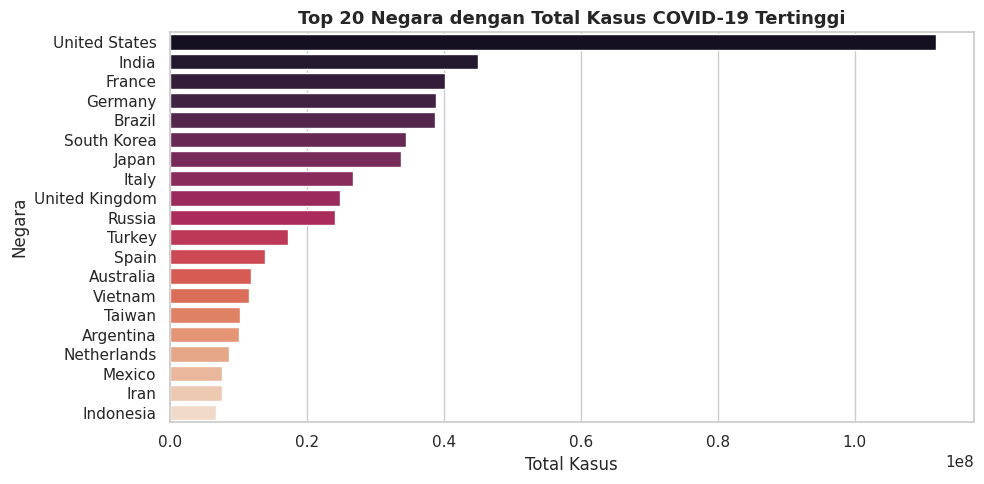

In [14]:
top10_covid = df_prep.sort_values(by='covid_cases', ascending=False).head(20)

plt.figure(figsize=(10, 5))
sns.barplot(data=top10_covid, x='covid_cases', y='country', palette='rocket', hue='country', legend=False)
plt.title("Top 20 Negara dengan Total Kasus COVID-19 Tertinggi", fontsize=13, weight='bold')
plt.xlabel("Total Kasus")
plt.ylabel("Negara")
plt.tight_layout()
plt.show()

## 7.2 Distribusi Suhu Terkini Ibukota per Wilayah

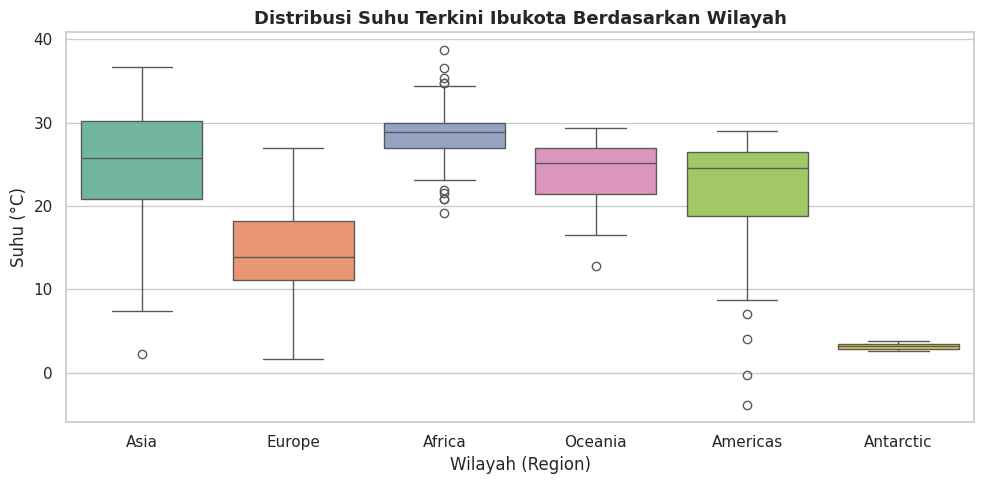

In [15]:
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df_final,
    x='region',
    y='capital_temp_c',
    hue='region',
    palette='Set2',
    legend=False,
)
plt.title(
    'Distribusi Suhu Terkini Ibukota Berdasarkan Wilayah',
    fontsize=13,
    weight='bold',
)
plt.xlabel('Wilayah (Region)')
plt.ylabel('Suhu (°C)')
plt.tight_layout()
plt.show()

## 7.3 Matriks Korelasi Antar-Indikator Utama

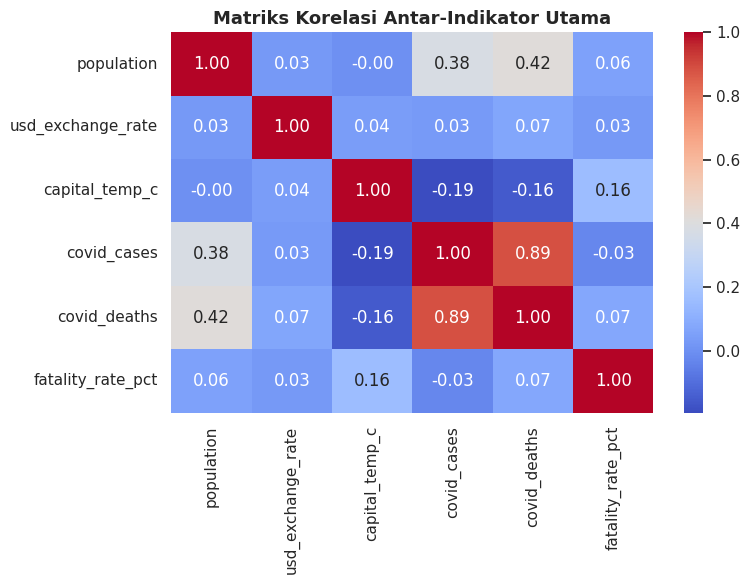

In [16]:
corr_cols = ['population', 'usd_exchange_rate', 'capital_temp_c', 'covid_cases', 'covid_deaths', 'fatality_rate_pct']
corr_matrix = df_prep[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", cbar=True)
plt.title("Matriks Korelasi Antar-Indikator Utama", fontsize=13, weight='bold')
plt.tight_layout()
plt.show()

## 7.4 Hubungan Populasi vs Total Kasus COVID-19

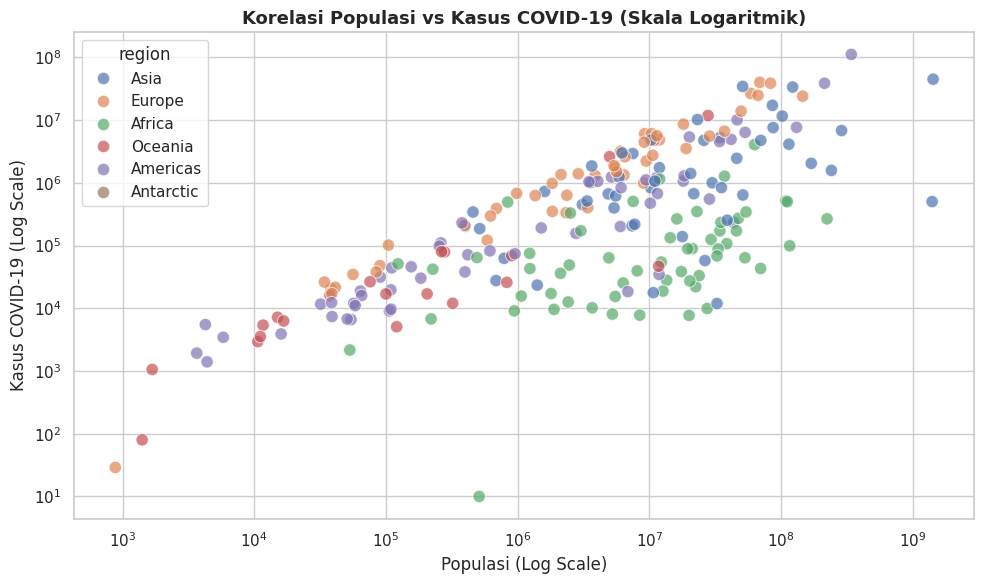

In [17]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_final, x='population', y='covid_cases', hue='region', alpha=0.7, s=80)
plt.xscale('log')
plt.yscale('log')
plt.title("Korelasi Populasi vs Kasus COVID-19 (Skala Logaritmik)", fontsize=13, weight='bold')
plt.xlabel("Populasi (Log Scale)")
plt.ylabel("Kasus COVID-19 (Log Scale)")
plt.tight_layout()
plt.show()